<a href="https://colab.research.google.com/github/davidlealo/sic_ia_2026/blob/main/ejercicios_profesor/sic2026_ia_clase04_taller_ml_gradio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diccionario de variables: `TV_Sales.csv`

**Origen:** adaptación del dataset *Carseats* de *An Introduction to Statistical Learning* (James, Witten, Hastie y Tibshirani). Los datos son simulados y describen ventas en 400 tiendas de una cadena. En esta versión se presentan como ventas de televisores.

**Dimensiones:** 400 filas (una por tienda) y 7 columnas. No hay valores faltantes.

**Cambios respecto al original:** columnas renombradas, precios (`comp_price` y `price`) multiplicados por 14, y se eliminaron las variables `Advertising`, `Population`, `Age` y `Education`.

---

## Resumen

| Variable | Nombre original | Tipo | Rol sugerido | Valores |
|---|---|---|---|---|
| `sales` | Sales | Numérica continua | Variable objetivo | 0 a 16.27 |
| `comp_price` | CompPrice | Numérica | Predictor | 1078 a 2450 |
| `income` | Income | Numérica | Predictor | 21 a 120 |
| `price` | Price | Numérica | Predictor | 336 a 2674 |
| `shelve_loc` | ShelveLoc | Categórica ordinal | Predictor | Bad, Medium, Good |
| `city` | Urban | Categórica binaria | Predictor | Yes, No |
| `local` | US | Categórica binaria | Predictor | Yes, No |

---

## Detalle por variable

### `sales`
Unidades vendidas en cada tienda, expresadas **en miles**. Un valor de 9.5 equivale a 9.500 televisores.

- Media: 7.50 · Desviación estándar: 2.82 · Mediana: 7.49
- Es la variable a predecir en problemas de **regresión**.
- Para **clasificación**, se suele binarizar: por ejemplo, venta alta si `sales > 8`.

### `comp_price`
Precio que cobra **el competidor** en la misma zona de la tienda.

- Media: 1749.65 · Rango: 1078 a 2450
- Relación esperada con `sales`: **positiva**. Si el competidor es caro, la tienda vende más.
- Su efecto se aprecia mejor en conjunto con `price`: lo que importa es el precio relativo.

### `income`
Nivel de **ingreso promedio de la comunidad** donde se ubica la tienda, en miles de dólares.

- Media: 68.66 · Rango: 21 a 120
- Relación esperada con `sales`: **positiva pero débil**.

### `price`
Precio que **la propia tienda** cobra por el producto.

- Media: 1621.13 · Rango: 336 a 2674
- Relación esperada con `sales`: **negativa y fuerte**. Es uno de los mejores predictores del dataset.

### `shelve_loc`
**Calidad de la ubicación del producto en la estantería** (góndola) dentro de la tienda.

| Nivel | Significado | Tiendas |
|---|---|---|
| `Bad` | Ubicación poco visible | 96 |
| `Medium` | Ubicación intermedia | 219 |
| `Good` | Ubicación destacada | 85 |

- Relación esperada con `sales`: **muy fuerte**. Las tiendas con `Good` venden bastante más que las con `Bad`.
- Al ser categórica, debe codificarse (variables *dummy* o *one-hot*). Al ser ordinal, también admite codificación 0, 1, 2.

### `city`
Indica si la tienda está en una **zona urbana** (`Yes`) o rural (`No`).

- Distribución: 282 `Yes` · 118 `No`
- Relación esperada con `sales`: **prácticamente nula**. Sirve como ejemplo de predictor no significativo.

### `local`
Indica si la tienda está en **el mercado doméstico** (`Yes`) o en el extranjero (`No`). En el original, `US` marca si la tienda está en Estados Unidos.

- Distribución: 258 `Yes` · 142 `No`
- Relación esperada con `sales`: **positiva**, pero con una advertencia importante (ver abajo).

> **Atención: posible variable proxy.** En el dataset original, las tiendas fuera de EE. UU. casi no reciben publicidad (`Advertising = 0`). Como esa columna fue eliminada, `local` absorbe parte del efecto de la publicidad. Un coeficiente positivo para `local` no implica que estar en el país aumente las ventas por sí mismo: refleja en buena medida una variable omitida. Es un buen ejemplo para discutir **sesgo por variable omitida** y la diferencia entre correlación y causalidad.

---

## Notas para el análisis

- Las variables categóricas (`shelve_loc`, `city`, `local`) deben codificarse antes de usar modelos de `scikit-learn`.
- `price` y `comp_price` están en la misma escala; `income` y `sales` no. Conviene **estandarizar** si se usan modelos sensibles a escala (regresión regularizada, KNN, SVM).
- Variables a destacar: `price` y `shelve_loc` (efecto fuerte) frente a `city` (efecto casi nulo).

In [ ]:
!wget https://raw.githubusercontent.com/davidlealo/sic_ia_2026/refs/heads/main/datos/cap05/TV_Sales.csv

--2026-10-20 23:32:12--  https://raw.githubusercontent.com/davidlealo/sic_ia_2026/refs/heads/main/datos/cap05/TV_Sales.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13021 (13K) [text/plain]
Saving to: ‘TV_Sales.csv’

TV_Sales.csv        100%[===================>]  12.72K  --.-KB/s    in 0s      

2026-10-20 23:32:12 (26.8 MB/s) - ‘TV_Sales.csv’ saved [13021/13021]



In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
import matplotlib.pyplot as plt

df = pd.read_csv("TV_Sales.csv")
y = (df["sales"] > 8).astype(int)
X = pd.get_dummies(df.drop(columns="sales"), drop_first=True)
arbol = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, y)

In [ ]:
print(export_text(arbol, feature_names=list(X.columns)))

|--- shelve_loc_Good <= 0.50
|   |--- price <= 1295.00
|   |   |--- income <= 57.00
|   |   |   |--- class: 0
|   |   |--- income >  57.00
|   |   |   |--- class: 1
|   |--- price >  1295.00
|   |   |--- shelve_loc_Medium <= 0.50
|   |   |   |--- class: 0
|   |   |--- shelve_loc_Medium >  0.50
|   |   |   |--- class: 0
|--- shelve_loc_Good >  0.50
|   |--- price <= 1995.00
|   |   |--- income <= 34.50
|   |   |   |--- class: 1
|   |   |--- income >  34.50
|   |   |   |--- class: 1
|   |--- price >  1995.00
|   |   |--- comp_price <= 2191.00
|   |   |   |--- class: 0
|   |   |--- comp_price >  2191.00
|   |   |   |--- class: 1



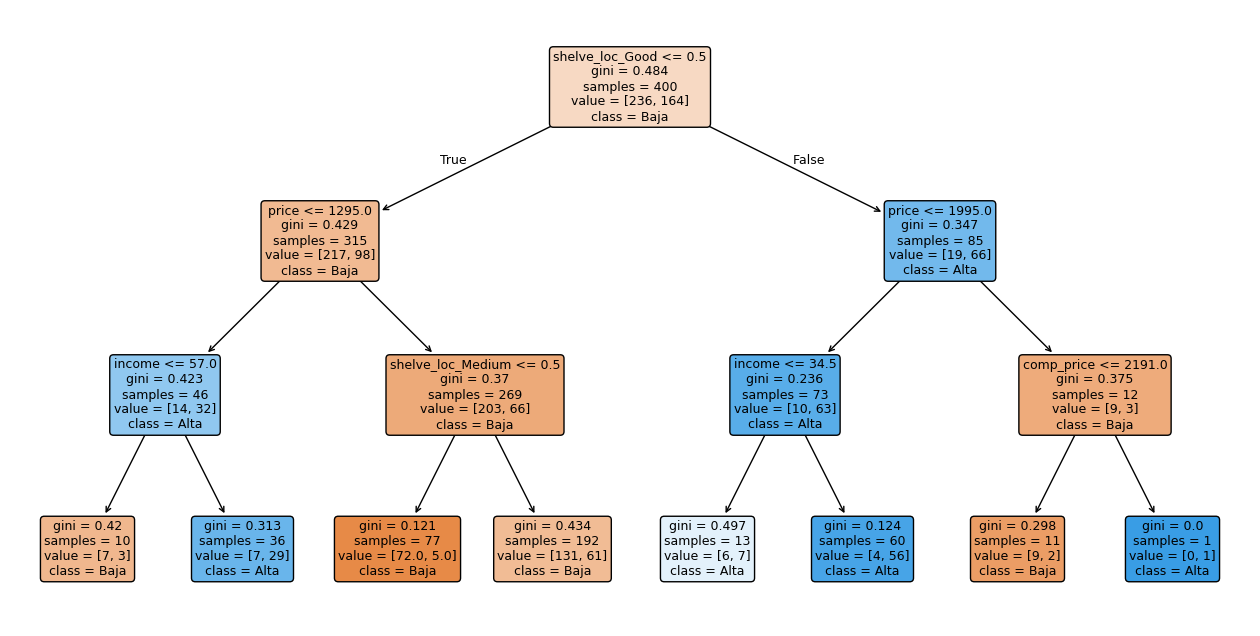

In [ ]:
plt.figure(figsize=(16, 8))
plot_tree(arbol, feature_names=X.columns, class_names=["Baja", "Alta"],
          filled=True, rounded=True, fontsize=9)
plt.show()

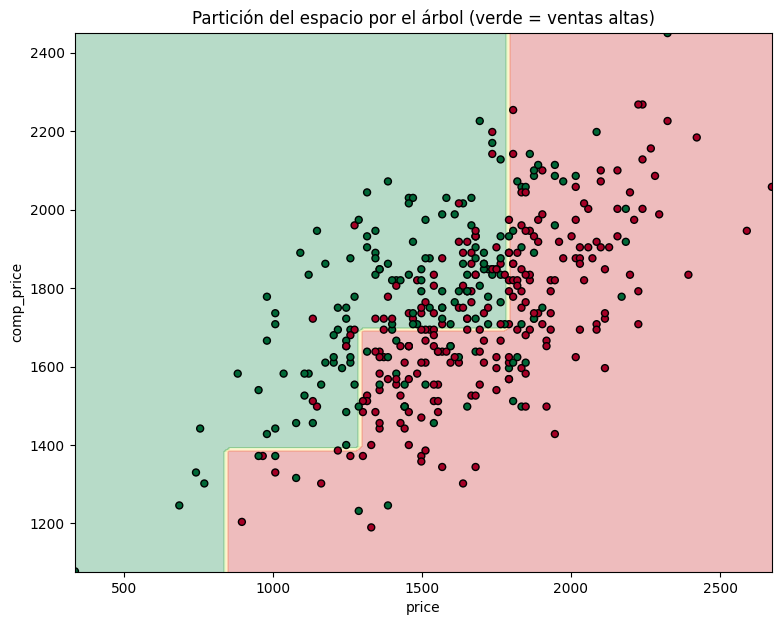

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import DecisionBoundaryDisplay

df = pd.read_csv("TV_Sales.csv")
X = df[["price", "comp_price"]]
y = (df["sales"] > 8).astype(int)
arbol = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, y)

fig, ax = plt.subplots(figsize=(9, 7))
DecisionBoundaryDisplay.from_estimator(arbol, X, response_method="predict",
                                       cmap="RdYlGn", alpha=0.3, ax=ax)
ax.scatter(X["price"], X["comp_price"], c=y, cmap="RdYlGn", edgecolor="k", s=25)
ax.set_xlabel("price"); ax.set_ylabel("comp_price")
ax.set_title("Partición del espacio por el árbol (verde = ventas altas)")
plt.savefig("particion.png", dpi=110, bbox_inches="tight")

|--- ubicacion <= 5.00
|   |--- class: 0
|--- ubicacion >  5.00
|   |--- precio <= 5.50
|   |   |--- class: 1
|   |--- precio >  5.50
|   |   |--- class: 0



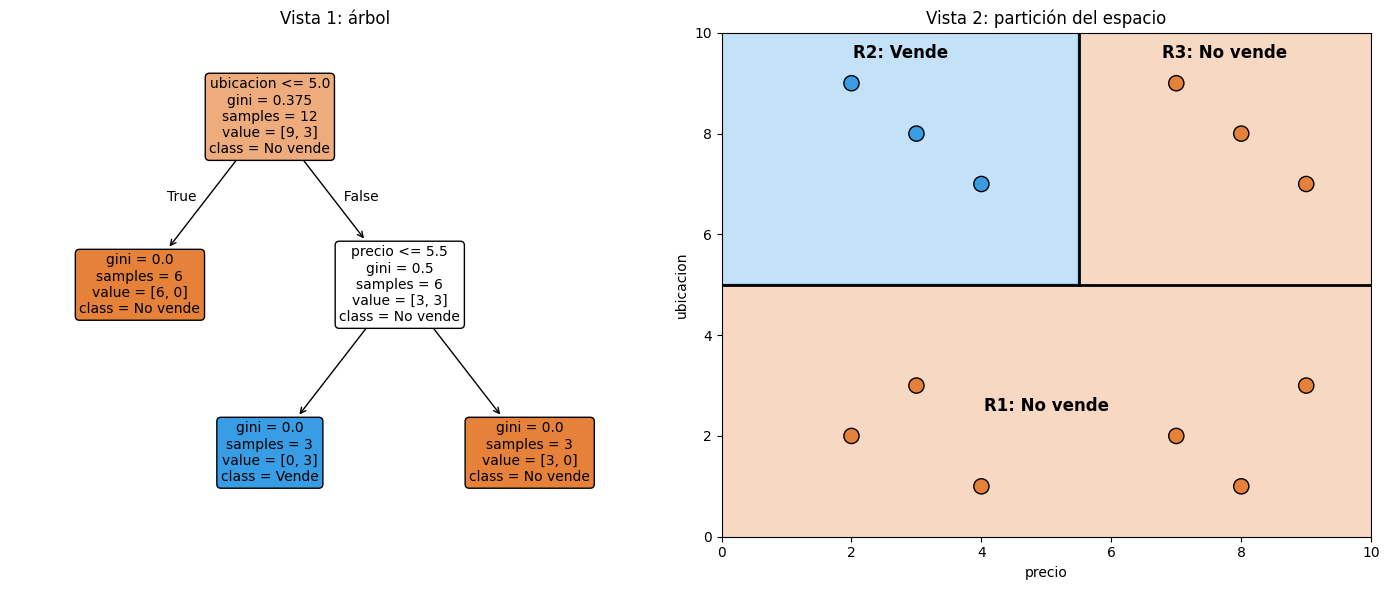

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

colores = ListedColormap(["#e58139", "#399de5"])  # mismos colores que plot_tree

# 12 tiendas inventadas: precio del TV (miles) y ubicación en góndola (1 a 10)
datos = pd.DataFrame({
    "precio":    [2, 3, 4, 3, 2, 4, 7, 8, 9, 8, 7, 9],
    "ubicacion": [2, 3, 1, 8, 9, 7, 2, 1, 3, 8, 9, 7],
    "vende":     [0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0],
})
X, y = datos[["precio", "ubicacion"]], datos["vende"]
arbol = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X, y)
print(export_text(arbol, feature_names=list(X.columns)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Vista 1: árbol con cuadros
plot_tree(arbol, feature_names=X.columns, class_names=["No vende", "Vende"],
          filled=True, rounded=True, fontsize=10, ax=ax1)
ax1.set_title("Vista 1: árbol")

# Vista 2: partición del espacio
DecisionBoundaryDisplay.from_estimator(arbol, X, response_method="predict",
    cmap=colores, alpha=0.3, ax=ax2, grid_resolution=300, eps=2)
ax2.scatter(X["precio"], X["ubicacion"], c=y, cmap=colores,
            edgecolor="k", s=120)
ax2.set_xlim(0, 10); ax2.set_ylim(0, 10)

# Líneas de corte y nombres de las regiones (hojas)
ax2.axhline(5, color="k", lw=2)                    # corte 1: ubicacion <= 5
ax2.plot([5.5, 5.5], [5, 10], color="k", lw=2)     # corte 2: precio <= 5.5
for x_txt, y_txt, txt in [(5, 2.5, "R1: No vende"), (2.75, 9.5, "R2: Vende"),
                          (7.75, 9.5, "R3: No vende")]:
    ax2.text(x_txt, y_txt, txt, ha="center", fontsize=12, weight="bold")
ax2.set_xlabel("precio"); ax2.set_ylabel("ubicacion")
ax2.set_title("Vista 2: partición del espacio")

plt.tight_layout()
plt.savefig("arbol_juguete.png", dpi=110)

### En los de votos podemos definir distintos pesos

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

# 1. Definir los modelos individuales
clf1 = LogisticRegression()
clf2 = RandomForestClassifier()
clf3 = GaussianNB()

# 2. Definir los estimadores (tuplas de 'nombre', modelo)
estimators_list = [
    ('lr', clf1),
    ('rf', clf2),
    ('gnb', clf3)
]

# 3. Asignar pesos a cada modelo en el mismo orden que 'estimators'
# En este caso: LogisticRegression (peso 2), RandomForest (peso 1), NaiveBayes (peso 1)
pesos = [2, 1, 1]

# 4. Crear el VotingClassifier especificando 'weights'
voting_model = VotingClassifier(
    estimators=estimators_list,
    voting='soft',   # Puede ser 'hard' o 'soft'
    weights=pesos    # Asignación de pesos
)

# 5. Entrenar el ensamble
# voting_model.fit(X_train, y_train)

# SIC 2026 · Inteligencia Artificial
## Clase 4: Presentaciones del Capítulo 5 y taller completo, de los datos a una app

**Samsung Innovation Campus Chile 2026 · ONG Innovacien**

La clase tiene dos partes:

1. **Presentaciones de los Grupos 2 y 3** del Capítulo 5, que quedaron pendientes de la clase anterior.
2. **Taller completo de machine learning**: vamos a recorrer de punta a punta el camino que sigue un proyecto real, desde cargar los datos hasta publicar una aplicación web que cualquier persona puede usar.

| Hora | Actividad |
|---|---|
| 18:00 a 18:10 | Inicio y orden de presentaciones |
| 18:10 a 18:50 | Presenta el **Grupo 2**: regresión lineal y logística |
| 18:50 a 19:30 | Presenta el **Grupo 3**: árboles, Naive Bayes, KNN, SVM y ensambles |
| 19:30 a 19:40 | Pausa |
| 19:40 a 21:50 | **Taller**: de los datos a una app con Gradio |
| 21:50 a 22:00 | Cierre |

Como en las clases anteriores, cada paso tiene una explicación, código que funciona y ejercicios con su celda de verificación. Las soluciones están al final.

---
# Parte 1. Presentaciones de los Grupos 2 y 3

Los grupos presentan desde el notebook de la Clase 3 (`clases/` en el [repositorio del curso](https://github.com/davidlealo/sic_ia_2026)). Mismo formato que el Grupo 1: explicación, ejemplo propio y un ejercicio para la clase, en 10 a 12 minutos por subgrupo.

| Orden | Subgrupo | Tema |
|---|---|---|
| 1 | 2A | Sesgo, varianza y regresión lineal |
| 2 | 2B | Diagnóstico de la regresión y otras regresiones |
| 3 | 2C | Regresión logística y sus métricas |
| 4 | 3A | Árbol de decisión |
| 5 | 3B | Naive Bayes, KNN y SVM |
| 6 | 3C | Algoritmos de conjunto |

**Mientras presentan**, completen la tabla de síntesis del final del notebook de la Clase 3. La vamos a necesitar en el taller, porque ahí elegiremos entre varios de estos algoritmos.

---
# Parte 2. Taller: de los datos a una app

## El problema

Una joyería quiere una herramienta para que sus vendedores sepan, con solo ingresar las características de un diamante, si corresponde a la gama **económica, media o premium** de precios. Vamos a construir esa herramienta.

## El camino completo

Este es el proceso que sigue casi cualquier proyecto de machine learning. Cada paso del taller es un minitutorial de una de estas etapas.

| Paso | Etapa | Pregunta que responde | Herramienta |
|---|---|---|---|
| 1 | Cargar los datos | ¿Qué información tenemos? | pandas |
| 2 | Definir el problema | ¿Qué queremos predecir exactamente? | pandas |
| 3 | Explorar | ¿Cómo son los datos? ¿Hay problemas? | pandas, seaborn |
| 4 | Dividir | ¿Con qué aprende y con qué se evalúa? | `train_test_split` |
| 5 | Preprocesar | ¿Cómo convertimos todo en números útiles? | `Pipeline`, `ColumnTransformer` |
| 6 | Línea base y primer modelo | ¿Cuánto acierta un modelo simple? | `DummyClassifier`, `LogisticRegression` |
| 7 | Comparar modelos | ¿Qué algoritmo funciona mejor? | `cross_val_score` |
| 8 | Ajustar hiperparámetros | ¿Cuál es la mejor configuración? | `GridSearchCV` |
| 9 | Evaluar | ¿Qué tan bueno es el modelo final? | `sklearn.metrics` |
| 10 | Guardar | ¿Cómo reutilizamos el modelo sin reentrenar? | `pickle` |
| 11 | Crear la app | ¿Cómo lo usa alguien que no programa? | Gradio |
| 12 | Publicar | ¿Cómo lo compartimos con el mundo? | Hugging Face Spaces |

Ejecuten la siguiente celda para preparar el entorno. Instala **Gradio**, que no viene en Colab, y define la función `revisar`.

In [ ]:
!pip install -q gradio

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

def revisar(condicion, mensaje_ok="Correcto.", mensaje_error="Todavía no. Revisa tu respuesta."):
    """Imprime si un ejercicio está bien resuelto."""
    try:
        print(mensaje_ok if condicion() else mensaje_error)
    except Exception:
        print(mensaje_error)

print("Listo.")

Listo.


---
## Paso 1. Cargar los datos

> **Definición. Dataset:** un conjunto de datos organizado en forma de tabla. Cada **fila** es una **observación** (aquí, un diamante) y cada **columna** es una **variable** o **característica** (aquí, su peso, su corte, su precio, etc.).

Usaremos el dataset **diamonds**, con cerca de 54.000 diamantes. Viene incluido en seaborn, así que no hay que descargar archivos. En un proyecto propio, normalmente cargarían un archivo con `pd.read_csv("archivo.csv")` o `pd.read_excel("archivo.xlsx")`.

| Columna | Significado |
|---|---|
| `carat` | Peso en quilates (1 quilate = 0,2 gramos) |
| `cut` | Calidad del corte: Fair, Good, Very Good, Premium, Ideal (de peor a mejor) |
| `color` | Color: de J (peor) a D (mejor, sin color) |
| `clarity` | Pureza: I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF (de peor a mejor) |
| `depth` | Profundidad total en porcentaje |
| `table` | Ancho de la cara superior en porcentaje |
| `price` | Precio en dólares |
| `x`, `y`, `z` | Largo, ancho y alto en milímetros |

In [ ]:
diamantes = sns.load_dataset("diamonds")
print("Forma:", diamantes.shape)
diamantes.head()

Forma: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [ ]:
diamantes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


**Qué mirar en `info()`:** el número de filas no nulas por columna (aquí no hay faltantes) y el tipo de cada columna. `cut`, `color` y `clarity` son de tipo `category`: son **variables categóricas**, que tendremos que convertir a números.

### Una decisión práctica: trabajar con una muestra

54.000 filas es bastante para entrenar muchos modelos durante una clase. Tomamos una **muestra aleatoria** de 10.000 diamantes. Con `random_state` fijo, todos obtenemos la misma muestra. En un proyecto real usarían todos los datos, o al menos verificarían que la muestra es representativa.

In [ ]:
datos = diamantes.sample(n=10_000, random_state=42).reset_index(drop=True)

# Convertimos las categóricas a texto simple para evitar sorpresas más adelante
for col in ["cut", "color", "clarity"]:
    datos[col] = datos[col].astype(str)

print("Filas en la muestra:", len(datos))

Filas en la muestra: 10000


---
## Paso 2. Definir el problema

Antes de escribir código de modelos hay que responder: **¿qué queremos predecir y con qué información?**

> **Definición. Variable objetivo (target, y):** lo que el modelo debe predecir.
>
> **Definición. Características (features, X):** la información que el modelo usa para predecir.

### ¿Clasificación o regresión?

- Si quisiéramos predecir el **precio exacto** (por ejemplo, 4.230 dólares), sería un problema de **regresión**: la respuesta es un número continuo.
- La joyería quiere saber la **gama de precio**: económica, media o premium. Eso es **clasificación**: la respuesta es una categoría.

Vamos a crear la variable objetivo dividiendo el precio en tres grupos del mismo tamaño con `pd.qcut`, que corta según **cuantiles** (cada grupo queda con un tercio de los diamantes).

In [ ]:
datos["gama"], cortes = pd.qcut(datos["price"], q=3, labels=["Económica", "Media", "Premium"], retbins=True)
datos["gama"] = datos["gama"].astype(str)

print("Límites de precio (USD):", cortes.round(0))
print(datos["gama"].value_counts())

Límites de precio (USD): [  335.  1215.  4211. 18823.]
gama
Media        3336
Económica    3333
Premium      3331
Name: count, dtype: int64


In [ ]:
datos

,carat,cut,color,clarity,depth,table,price,x,y,z,gama
0,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47,Económica
1,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26,Media
2,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95,Media
3,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98,Media
4,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61,Premium
...,...,...,...,...,...,...,...,...,...,...,...
9995,0.40,Premium,F,VS2,61.6,58.0,842,4.75,4.80,2.94,Económica
9996,0.91,Very Good,F,VS1,63.5,56.0,4739,6.18,6.14,3.91,Premium
9997,0.30,Very Good,H,VVS1,63.3,55.0,878,4.34,4.29,2.73,Económica
9998,0.35,Ideal,E,VS2,62.5,55.0,767,4.50,4.52,2.82,Económica


### Qué características usar

Vamos a usar `carat`, `cut`, `color`, `clarity`, `depth` y `table`. Dejamos fuera `x`, `y` y `z` porque dependen casi por completo del peso (`carat`) y harían la app más difícil de usar sin aportar mucho.

> **Definición. Fuga de datos (data leakage):** ocurre cuando el modelo recibe, entre sus características, información que no tendría disponible al momento de predecir, o que contiene la respuesta.
>
> Aquí sería un error gravísimo incluir `price` como característica: la gama se calculó a partir del precio, así que el modelo acertaría casi siempre en el entrenamiento y sería inútil en la vida real, donde justamente no conocemos el precio.

In [ ]:
CARACTERISTICAS = ["carat", "cut", "color", "clarity", "depth", "table"]
NUMERICAS = ["carat", "depth", "table"]
CATEGORICAS = ["cut", "color", "clarity"]
OBJETIVO = "gama"

### Ejercicio 1
Crea `precio_mediano_por_gama`: una Series con el **precio mediano** de cada gama. ¿Tiene sentido el orden?

In [ ]:
precio_mediano_por_gama = datos.groupby("gama")["price"].median().sort_values()
precio_mediano_por_gama

,price
gama,
Económica,766.0
Media,2386.0
Premium,7085.0


In [ ]:
revisar(lambda: np.allclose(precio_mediano_por_gama.sort_index().values,
                            datos.groupby("gama")["price"].median().sort_index().values))

Correcto.


---
## Paso 3. Explorar los datos (EDA)

> **Definición. Análisis exploratorio de datos (EDA):** revisar los datos con estadísticas y gráficos antes de modelar, para entenderlos y detectar problemas (faltantes, valores extraños, clases desbalanceadas).

Tres preguntas rápidas:

1. ¿Las clases están **balanceadas**? Sí, por construcción: cada gama tiene un tercio.
2. ¿Qué característica numérica separa mejor las gamas?
3. ¿Las categóricas se relacionan con la gama?

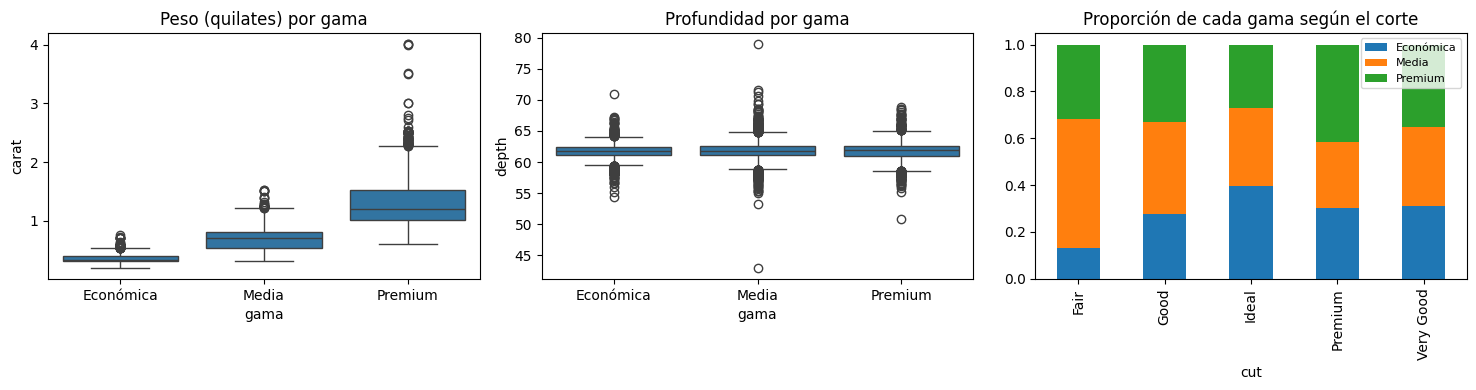

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
orden = ["Económica", "Media", "Premium"]
sns.boxplot(data=datos, x="gama", y="carat", order=orden, ax=ejes[0]); ejes[0].set_title("Peso (quilates) por gama")
sns.boxplot(data=datos, x="gama", y="depth", order=orden, ax=ejes[1]); ejes[1].set_title("Profundidad por gama")
pd.crosstab(datos["cut"], datos["gama"], normalize="index")[orden].plot(kind="bar", stacked=True, ax=ejes[2])
ejes[2].set_title("Proporción de cada gama según el corte"); ejes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura:** el peso separa muy bien las gamas, la profundidad casi nada. Ya sabemos qué variable va a importar más. Lo verificaremos en el Paso 9 con la importancia de variables.

**Pregunta para pensar:** en el gráfico de corte, los cortes "Ideal" no son los que más aparecen en la gama Premium. ¿Por qué podría ser? (Pista: ¿los diamantes grandes suelen tener el mejor corte?)

---
## Paso 4. Dividir en entrenamiento y prueba

> **Definición. Conjunto de entrenamiento:** los datos con los que el modelo aprende.
>
> **Definición. Conjunto de prueba (test):** datos que se apartan al inicio y que el modelo **no ve** hasta la evaluación final. Simulan los diamantes nuevos que llegarán a la joyería.

Regla de oro: **el conjunto de prueba se usa una sola vez, al final**. Todas las decisiones (qué modelo, qué hiperparámetros) se toman solo con el entrenamiento, usando validación cruzada.

`stratify=y` mantiene la misma proporción de cada gama en ambos conjuntos.

In [ ]:
from sklearn.model_selection import train_test_split

X = datos[CARACTERISTICAS]
y = datos[OBJETIVO]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3))

Entrenamiento: (8000, 6) | Prueba: (2000, 6)
gama
Media        0.334
Económica    0.333
Premium      0.333
Name: proportion, dtype: float64


In [ ]:
datos.describe()

,carat,depth,table,price,x,y,z
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,0.795464,61.77341,57.447340,3900.356600,5.722033,5.723494,3.534455
std,0.476937,1.45393,2.255054,3992.251932,1.128186,1.120839,0.696424
min,0.200000,43.00000,49.000000,335.000000,0.000000,0.000000,0.000000
25%,0.400000,61.10000,56.000000,929.750000,4.690000,4.700000,2.900000
50%,0.700000,61.90000,57.000000,2385.500000,5.690000,5.700000,3.520000
75%,1.040000,62.50000,59.000000,5235.250000,6.530000,6.530000,4.030000
max,4.010000,79.00000,73.000000,18823.000000,10.140000,10.100000,6.310000


---
## Paso 5. Preprocesar con un Pipeline

Los modelos necesitan números en escalas comparables. Tenemos que:

- **Escalar** las numéricas (`carat`, `depth`, `table`) con `StandardScaler`.
- **Codificar** las categóricas. Como `cut`, `color` y `clarity` tienen un **orden natural** (de peor a mejor), usamos `OrdinalEncoder` con el orden explícito, en vez de one-hot.

> **Definición. Codificación ordinal:** asigna 0, 1, 2... respetando un orden con sentido (Fair = 0, Good = 1, ..., Ideal = 4). Se usa cuando la categoría tiene jerarquía.
>
> **Definición. Codificación one-hot:** crea una columna de 0 y 1 por categoría. Se usa cuando no hay orden (por ejemplo, comunas o colores de auto).

### ¿Por qué un Pipeline?

> **Definición. ColumnTransformer:** aplica transformaciones distintas a columnas distintas (escalar unas, codificar otras) y junta el resultado.
>
> **Definición. Pipeline:** encadena el preprocesamiento y el modelo en **un solo objeto**. Cuando llamamos a `fit`, ajusta todo en orden; cuando llamamos a `predict`, aplica las mismas transformaciones y luego predice.

El Pipeline resuelve dos problemas:

1. **Evita fugas de datos.** En la validación cruzada, el escalador se ajusta solo con los datos de entrenamiento de cada pliegue.
2. **Simplifica el guardado.** Al guardar el Pipeline se guarda todo: preprocesamiento y modelo. La app recibirá los datos tal como los escribe una persona ("Ideal", "D", 0,7) y el Pipeline se encargará del resto.

In [ ]:
X

,carat,cut,color,clarity,depth,table
0,0.24,Ideal,G,VVS1,62.1,56.0
1,0.58,Very Good,F,VVS2,60.0,57.0
2,0.40,Ideal,E,VVS2,62.1,55.0
3,0.43,Premium,E,VVS2,60.8,57.0
4,1.55,Ideal,E,SI2,62.3,55.0
...,...,...,...,...,...,...
9995,0.40,Premium,F,VS2,61.6,58.0
9996,0.91,Very Good,F,VS1,63.5,56.0
9997,0.30,Very Good,H,VVS1,63.3,55.0
9998,0.35,Ideal,E,VS2,62.5,55.0


In [ ]:
y

,gama
0,Económica
1,Media
2,Media
3,Media
4,Premium
...,...
9995,Económica
9996,Premium
9997,Económica
9998,Económica


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline

ORDEN_CUT = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
ORDEN_COLOR = ["J", "I", "H", "G", "F", "E", "D"]
ORDEN_CLARITY = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]

preprocesador = ColumnTransformer([
    ("numericas", StandardScaler(), NUMERICAS),
    ("categoricas", OrdinalEncoder(categories=[ORDEN_CUT, ORDEN_COLOR, ORDEN_CLARITY]), CATEGORICAS),
])

# Veamos qué produce el preprocesador con las primeras 3 filas
print(X_train.head(3))
print(preprocesador.fit_transform(X_train)[:3].round(2))

      carat        cut color clarity  depth  table
2146   1.07  Very Good     E     VS2   60.4   58.0
7182   0.74    Premium     E     SI2   58.8   60.0
1942   0.51    Premium     G     VS1   62.1   60.0
[[ 0.57 -0.95  0.25  2.    5.    3.  ]
 [-0.12 -2.06  1.14  3.    5.    1.  ]
 [-0.6   0.22  1.14  3.    3.    4.  ]]


In [ ]:
X_train["cut"]

,cut
2146,Very Good
7182,Premium
1942,Premium
1158,Premium
8166,Fair
...,...
7617,Premium
411,Very Good
1336,Ideal
2097,Ideal


---
## Paso 6. Línea base y primer modelo

> **Definición. Línea base (baseline):** el resultado de la estrategia más simple posible. Cualquier modelo útil tiene que superarla.

Con tres clases del mismo tamaño, adivinar siempre la misma acierta un tercio. Ese es el piso.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

base = Pipeline([("prep", preprocesador), ("modelo", DummyClassifier(strategy="most_frequent"))])
base.fit(X_train, y_train)
print("Exactitud de la línea base (en entrenamiento):", round(base.score(X_train, y_train), 3))

primer_modelo = Pipeline([("prep", preprocesador), ("modelo", LogisticRegression(max_iter=2000))])
primer_modelo.fit(X_train, y_train)
print("Exactitud de la regresión logística (en entrenamiento):", round(primer_modelo.score(X_train, y_train), 3))

Exactitud de la línea base (en entrenamiento): 0.334
Exactitud de la regresión logística (en entrenamiento): 0.941


Atención: estos números son **en entrenamiento**, así que son optimistas. No podemos usar el conjunto de prueba todavía. ¿Cómo estimamos entonces el desempeño en datos nuevos? Con validación cruzada.

---
## Paso 7. Comparar modelos con validación cruzada

> **Definición. Validación cruzada de k pliegues (k-fold):** divide el entrenamiento en k partes. Entrena k veces, cada vez dejando una parte fuera para evaluar, y promedia los k resultados. Así se estima el desempeño en datos nuevos **sin tocar el conjunto de prueba**.

```
Pliegue 1: [VAL][ent][ent][ent][ent]
Pliegue 2: [ent][VAL][ent][ent][ent]
...
Pliegue 5: [ent][ent][ent][ent][VAL]
```

La desviación estándar de los k resultados también importa: indica qué tan estable es el modelo.

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

candidatos = {
    "Regresión logística": LogisticRegression(max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

resultados = {}
for nombre, modelo in candidatos.items():
    pipe = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    puntajes = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    resultados[nombre] = puntajes
    print(f"{nombre:20s} exactitud CV: {puntajes.mean():.3f} (+/- {puntajes.std():.3f})")

Regresión logística  exactitud CV: 0.941 (+/- 0.006)
KNN                  exactitud CV: 0.821 (+/- 0.010)
Árbol de decisión    exactitud CV: 0.935 (+/- 0.006)
Random forest        exactitud CV: 0.944 (+/- 0.005)


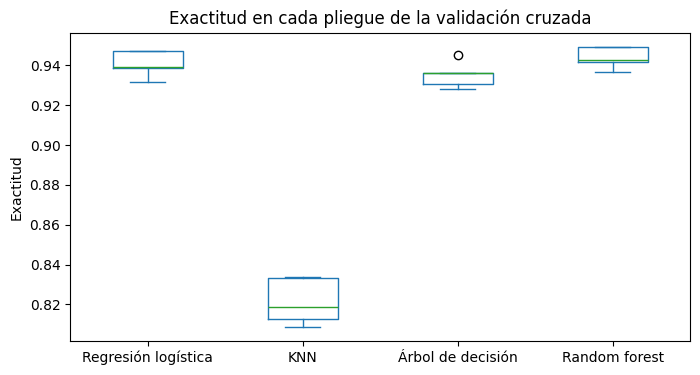

In [ ]:
pd.DataFrame(resultados).plot(kind="box", figsize=(8, 4), title="Exactitud en cada pliegue de la validación cruzada")
plt.ylabel("Exactitud"); plt.show()

### Ejercicio 2
Agrega a la comparación un **Gradient Boosting** (`GradientBoostingClassifier(random_state=42)`) usando el mismo `preprocesador` y el mismo `cv`. Guarda el promedio de sus puntajes en `exac_gb`.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

exac_gb = None  # TU CÓDIGO AQUÍ
print("Gradient boosting:", exac_gb)

In [ ]:
_ref = cross_val_score(Pipeline([("prep", preprocesador), ("modelo", GradientBoostingClassifier(random_state=42))]),
                       X_train, y_train, cv=cv).mean()
revisar(lambda: np.isclose(exac_gb, _ref))

---
## Paso 8. Ajustar hiperparámetros con GridSearchCV

El random forest fue el mejor (o de los mejores). Ahora buscamos su **mejor configuración**.

> **Definición. Hiperparámetro:** un ajuste del modelo que elegimos nosotros antes de entrenar, como el número de árboles (`n_estimators`) o la profundidad máxima (`max_depth`).
>
> **Definición. GridSearchCV:** prueba **todas las combinaciones** de una grilla de hiperparámetros, evalúa cada una con validación cruzada y se queda con la mejor. Al terminar, reentrena la mejor combinación con todo el entrenamiento (`refit=True`).

En un Pipeline, los hiperparámetros se nombran con el formato `paso__parametro` (dos guiones bajos). Por ejemplo, `modelo__max_depth` es el `max_depth` del paso llamado `modelo`.

¿Cuántos modelos entrena esta grilla? 2 × 2 × 2 = 8 combinaciones, por 5 pliegues = **40 entrenamientos**. Por eso la grilla es pequeña: puede tardar uno o dos minutos.

In [ ]:
from sklearn.model_selection import GridSearchCV

pipe_rf = Pipeline([("prep", preprocesador), ("modelo", RandomForestClassifier(random_state=42, n_jobs=-1))])

grilla = {
    "modelo__n_estimators": [100, 300],
    "modelo__max_depth": [10, 20],
    "modelo__min_samples_leaf": [1, 5],
}

busqueda = GridSearchCV(pipe_rf, grilla, cv=cv, scoring="accuracy", n_jobs=-1)
busqueda.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda.best_params_)
print("Mejor exactitud CV:", round(busqueda.best_score_, 3))

Mejores hiperparámetros: {'modelo__max_depth': 20, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 300}
Mejor exactitud CV: 0.946


In [ ]:
# Todas las combinaciones ordenadas por desempeño
tabla = pd.DataFrame(busqueda.cv_results_)
tabla[["param_modelo__n_estimators", "param_modelo__max_depth", "param_modelo__min_samples_leaf",
       "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False).head(6).round(3)

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score
5,300,20,1,0.946,0.006
4,100,20,1,0.944,0.006
7,300,20,5,0.940,0.005
0,100,10,1,0.940,0.004
1,300,10,1,0.940,0.006
6,100,20,5,0.940,0.006


**Qué observar:** a veces la diferencia entre la mejor combinación y la quinta es mínima. En ese caso conviene elegir la más simple (menos árboles, menos profundidad), porque es más rápida y menos propensa a sobreajustar.

### Ejercicio 3
¿Cuántos entrenamientos haría `GridSearchCV` con la grilla de abajo y 5 pliegues? Calcúlalo con código usando `len` y guárdalo en `n_entrenamientos`.

In [ ]:
grilla_grande = {
    "modelo__n_estimators": [100, 200, 300, 500],
    "modelo__max_depth": [None, 5, 10, 20, 30],
    "modelo__min_samples_leaf": [1, 2, 5],
}
n_entrenamientos = len(grilla_grande["modelo__n_estimators"]) * len(grilla_grande["modelo__max_depth"]) \
                   * len(grilla_grande["modelo__min_samples_leaf"]) * 5
print(n_entrenamientos)

300


In [ ]:
revisar(lambda: n_entrenamientos == 4 * 5 * 3 * 5)

Correcto.


---
## Paso 9. Evaluar el modelo final

Ahora sí, y **una sola vez**, evaluamos con el conjunto de prueba. `busqueda.best_estimator_` es el Pipeline completo con los mejores hiperparámetros, ya reentrenado.

Métricas que usamos (las vio el Grupo 1D):

> **Exactitud (accuracy):** proporción de aciertos totales.
>
> **Precision de una clase:** de los que el modelo dijo que eran de esa clase, cuántos lo eran.
>
> **Recall de una clase:** de los que realmente eran de esa clase, cuántos detectó el modelo.
>
> **F1:** promedio armónico de precision y recall. Es alto solo si ambas lo son.
>
> **Promedio macro:** promedia la métrica de cada clase dándoles el mismo peso. **Promedio ponderado (weighted):** pondera según cuántos casos tiene cada clase.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

modelo_final = busqueda.best_estimator_
pred = modelo_final.predict(X_test)

print(f"Exactitud en prueba: {accuracy_score(y_test, pred):.3f}")
print(f"F1 macro en prueba:  {f1_score(y_test, pred, average='macro'):.3f}")
print()
print(classification_report(y_test, pred, digits=3))

Exactitud en prueba: 0.949
F1 macro en prueba:  0.949

              precision    recall  f1-score   support

   Económica      0.982     0.966     0.974       667
       Media      0.923     0.922     0.923       667
     Premium      0.941     0.958     0.949       666

    accuracy                          0.949      2000
   macro avg      0.949     0.949     0.949      2000
weighted avg      0.949     0.949     0.949      2000



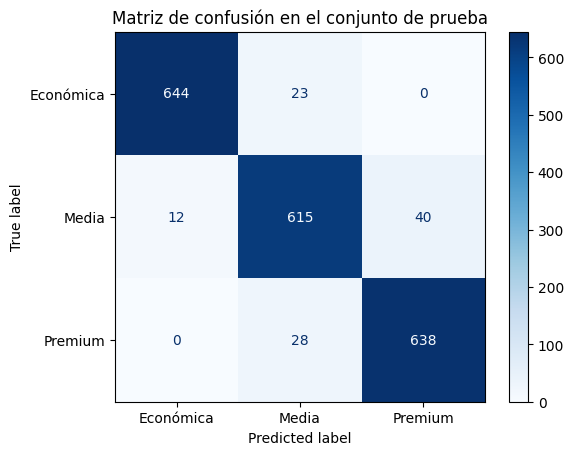

In [ ]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=["Económica", "Media", "Premium"], cmap="Blues")
plt.title("Matriz de confusión en el conjunto de prueba"); plt.show()

**Lectura de la matriz:** los errores aparecen casi solo entre gamas **vecinas** (Económica con Media, Media con Premium). El modelo casi nunca confunde un diamante económico con uno premium. Es el tipo de error que esperaríamos, porque los diamantes cerca del límite entre gamas son parecidos.

### ¿Qué aprendió el modelo?

> **Definición. Importancia de variables:** en un random forest, mide cuánto contribuye cada característica a mejorar las divisiones de los árboles. Suma 1.

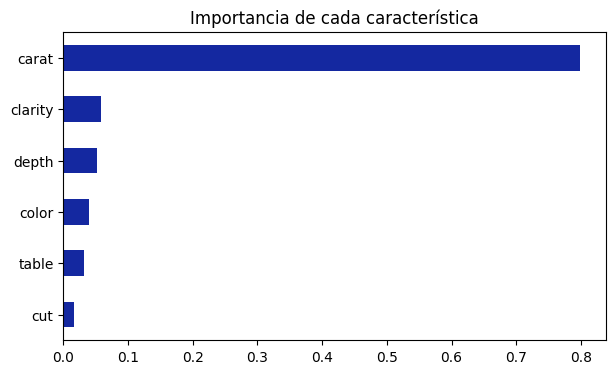

In [ ]:
importancias = pd.Series(modelo_final.named_steps["modelo"].feature_importances_, index=NUMERICAS + CATEGORICAS).sort_values()
importancias.plot(kind="barh", color="#1428A0", figsize=(7, 4), title="Importancia de cada característica")
plt.show()

Coincide con el EDA del Paso 3: el peso (`carat`) domina, y la pureza y el color ayudan a afinar.

### ¿El modelo está listo?

Antes de guardar, nos preguntamos:

- ¿Supera claramente a la línea base? Sí: de 0,33 a cerca de 0,9.
- ¿La exactitud en prueba es parecida a la de validación cruzada? Si fuera mucho menor, habría sobreajuste o fuga de datos.
- ¿Los errores son aceptables para el uso? Confundir gamas vecinas es tolerable para orientar a un vendedor.
- ¿Vale la pena su complejidad? En el Paso 7, la regresión logística quedó muy cerca del random forest. Un random forest con cientos de árboles puede pesar varios MB y es más lento; una regresión logística pesa unos pocos KB. Si la diferencia de desempeño es mínima, el modelo simple suele ser la mejor elección para producción. Aquí seguimos con el random forest para practicar `GridSearchCV`.

In [ ]:
print(f"Exactitud CV: {busqueda.best_score_:.3f} | Exactitud en prueba: {accuracy_score(y_test, pred):.3f}")

Exactitud CV: 0.946 | Exactitud en prueba: 0.949


---
## Paso 10. Guardar el modelo con pickle

Entrenar puede tardar minutos u horas. No queremos repetirlo cada vez que alguien use la app.

> **Definición. Serializar:** convertir un objeto de Python (aquí, el Pipeline entrenado) en un archivo, para cargarlo después exactamente igual.
>
> **Definición. pickle:** el módulo de Python para serializar objetos. Los archivos suelen tener extensión `.pkl` o `.pickle`.

Buenas prácticas al guardar:

1. **Guardar el Pipeline completo**, no solo el modelo. Así el archivo incluye el preprocesamiento.
2. **Guardar información adicional**: características que espera, clases, métricas y versión de scikit-learn. Un modelo guardado con una versión puede fallar al cargarse con otra.
3. **Seguridad:** nunca abran un archivo pickle de origen desconocido. Al cargarlo se puede ejecutar código arbitrario.

In [ ]:
import pickle
import sklearn

paquete = {
    "modelo": modelo_final,
    "caracteristicas": CARACTERISTICAS,
    "clases": list(modelo_final.classes_),
    "exactitud_prueba": round(accuracy_score(y_test, pred), 3),
    "version_sklearn": sklearn.__version__,
}

with open("modelo_diamantes.pkl", "wb") as archivo:   # "wb": escribir en modo binario
    pickle.dump(paquete, archivo)

import os
print(f"Archivo guardado: {os.path.getsize('modelo_diamantes.pkl') / 1e6:.1f} MB")

Archivo guardado: 34.9 MB


### Cargar el modelo y verificar

Simulamos lo que hará la app: cargar el archivo y predecir. Las predicciones deben ser **idénticas** a las del modelo original.

In [ ]:
with open("modelo_diamantes.pkl", "rb") as archivo:   # "rb": leer en modo binario
    cargado = pickle.load(archivo)

modelo_cargado = cargado["modelo"]
print("Clases:", cargado["clases"], "| Exactitud guardada:", cargado["exactitud_prueba"])
print("¿Predicciones idénticas?", (modelo_cargado.predict(X_test) == pred).all())

# Un diamante nuevo, escrito tal como lo ingresaría una persona
nuevo = pd.DataFrame([{"carat": 0.9, "cut": "Ideal", "color": "E", "clarity": "VS1", "depth": 61.5, "table": 56}])
print("Predicción:", modelo_cargado.predict(nuevo)[0])
print("Probabilidades:", {c: round(float(p), 3) for c, p in zip(modelo_cargado.classes_, modelo_cargado.predict_proba(nuevo)[0])})

Clases: ['Económica', 'Media', 'Premium'] | Exactitud guardada: 0.949
¿Predicciones idénticas? True
Predicción: Premium
Probabilidades: {'Económica': 0.0, 'Media': 0.123, 'Premium': 0.877}


Para descargar el archivo a su computador, ejecuten `from google.colab import files; files.download("modelo_diamantes.pkl")`. Lo necesitarán si publican la app en el Paso 12.

### Ejercicio 4
Usando `modelo_cargado`, predice la gama de un diamante de **2,0 quilates**, corte **"Premium"**, color **"G"**, pureza **"SI1"**, profundidad **62** y tabla **58**. Guarda la predicción (el texto de la gama) en `gama_predicha`.

In [ ]:
gama_predicha = None  # TU CÓDIGO AQUÍ
print(gama_predicha)

In [ ]:
_d = pd.DataFrame([{"carat": 2.0, "cut": "Premium", "color": "G", "clarity": "SI1", "depth": 62, "table": 58}])
revisar(lambda: gama_predicha == modelo_cargado.predict(_d)[0])

---
## Paso 11. Crear una app con Gradio

> **Definición. Gradio:** librería de Python para crear una interfaz web para un modelo con pocas líneas de código. La persona ve campos para ingresar datos y un botón; no necesita saber programar.

Una app de Gradio tiene tres piezas:

1. **Una función de Python** que recibe las entradas y devuelve el resultado. Aquí: recibe las características de un diamante y devuelve las probabilidades de cada gama.
2. **Componentes de entrada** (`inputs`): deslizadores, menús desplegables, cajas de texto, imágenes, etc.
3. **Componentes de salida** (`outputs`): aquí, `gr.Label`, que muestra las clases con sus probabilidades como barras.

`gr.Interface` une las tres piezas y `launch()` levanta la app.

### 11.1 La función de predicción

Primero la probamos sola, sin interfaz. Si la función funciona, la app funcionará.

In [ ]:
import gradio as gr

with open("modelo_diamantes.pkl", "rb") as archivo:
    paquete_app = pickle.load(archivo)
modelo_app = paquete_app["modelo"]

def predecir_gama(carat, cut, color, clarity, depth, table):
    """Recibe las características de un diamante y devuelve la probabilidad de cada gama."""
    diamante = pd.DataFrame([{"carat": carat, "cut": cut, "color": color,
                              "clarity": clarity, "depth": depth, "table": table}])
    probabilidades = modelo_app.predict_proba(diamante)[0]
    return {clase: float(p) for clase, p in zip(modelo_app.classes_, probabilidades)}

# Prueba de la función
predecir_gama(0.9, "Ideal", "E", "VS1", 61.5, 56)

{'Económica': 0.0, 'Media': 0.12333333333333334, 'Premium': 0.8766666666666667}

### 11.2 La interfaz

Cada componente de entrada corresponde, **en el mismo orden**, a un argumento de la función. Los rangos de los deslizadores salen de los datos, para que la persona no ingrese valores que el modelo nunca vio.

`share=True` genera un link público temporal (dura 72 horas) que pueden abrir desde el celular o enviar a otra persona. La app funciona mientras esta sesión de Colab esté activa.

In [ ]:
app = gr.Interface(
    fn=predecir_gama,
    inputs=[
        gr.Slider(0.2, 3.0, value=0.7, step=0.01, label="Peso (quilates)"),
        gr.Dropdown(ORDEN_CUT, value="Ideal", label="Corte"),
        gr.Dropdown(ORDEN_COLOR[::-1], value="G", label="Color (D es el mejor)"),
        gr.Dropdown(ORDEN_CLARITY[::-1], value="VS2", label="Pureza (IF es la mejor)"),
        gr.Slider(55, 70, value=61.8, step=0.1, label="Profundidad (%)"),
        gr.Slider(50, 70, value=57, step=0.5, label="Tabla (%)"),
    ],
    outputs=gr.Label(num_top_classes=3, label="Gama de precio estimada"),
    title="Estimador de gama de precio de diamantes",
    description="Ingresa las características del diamante para estimar si corresponde a la gama económica, media o premium.",
    examples=[
        [0.3, "Ideal", "E", "VS1", 61.5, 56],
        [0.9, "Very Good", "G", "SI1", 62.0, 58],
        [1.8, "Premium", "F", "VS2", 61.0, 59],
    ],
)

In [ ]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1477284a9a47de170a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### Ejercicio 5
Modifica la función para que, además de las probabilidades, la app muestre un **rango de precio orientativo** en dólares según la gama más probable, usando los límites `cortes` del Paso 2. Pistas:

- La función debe devolver **dos** valores: el diccionario de probabilidades y un texto.
- `outputs` pasa a ser una lista: `[gr.Label(...), gr.Textbox(label="Rango orientativo")]`.

Este ejercicio no tiene verificación automática: la prueba es que la app funcione.

In [ ]:
# TU CÓDIGO AQUÍ

---
## Paso 12. Publicar la app en Hugging Face Spaces

El link de `share=True` muere cuando se cierra Colab. Para una app **permanente y gratuita** se usa **Hugging Face Spaces**.

> **Definición. Hugging Face Spaces:** servicio que aloja apps de machine learning hechas con Gradio (u otras herramientas). Basta con subir tres archivos.

Los tres archivos son:

| Archivo | Contenido |
|---|---|
| `app.py` | El código de la app: cargar el modelo, la función y la interfaz |
| `requirements.txt` | Las librerías que necesita, con la versión de scikit-learn del Paso 10 |
| `modelo_diamantes.pkl` | El modelo guardado |

La siguiente celda escribe `app.py` y `requirements.txt` con lo que construimos.

In [ ]:
codigo_app = '''import pickle
import pandas as pd
import gradio as gr

with open("modelo_diamantes.pkl", "rb") as archivo:
    modelo = pickle.load(archivo)["modelo"]

ORDEN_CUT = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
ORDEN_COLOR = ["D", "E", "F", "G", "H", "I", "J"]
ORDEN_CLARITY = ["IF", "VVS1", "VVS2", "VS1", "VS2", "SI1", "SI2", "I1"]

def predecir_gama(carat, cut, color, clarity, depth, table):
    diamante = pd.DataFrame([{"carat": carat, "cut": cut, "color": color,
                              "clarity": clarity, "depth": depth, "table": table}])
    probabilidades = modelo.predict_proba(diamante)[0]
    return {clase: float(p) for clase, p in zip(modelo.classes_, probabilidades)}

app = gr.Interface(
    fn=predecir_gama,
    inputs=[
        gr.Slider(0.2, 3.0, value=0.7, step=0.01, label="Peso (quilates)"),
        gr.Dropdown(ORDEN_CUT, value="Ideal", label="Corte"),
        gr.Dropdown(ORDEN_COLOR, value="G", label="Color (D es el mejor)"),
        gr.Dropdown(ORDEN_CLARITY, value="VS2", label="Pureza (IF es la mejor)"),
        gr.Slider(55, 70, value=61.8, step=0.1, label="Profundidad (%)"),
        gr.Slider(50, 70, value=57, step=0.5, label="Tabla (%)"),
    ],
    outputs=gr.Label(num_top_classes=3, label="Gama de precio estimada"),
    title="Estimador de gama de precio de diamantes",
)

app.launch()
'''

with open("app.py", "w", encoding="utf-8") as f:
    f.write(codigo_app)
with open("requirements.txt", "w") as f:
    f.write(f"scikit-learn=={sklearn.__version__}\npandas\n")

print(open("requirements.txt").read())

### Paso a paso para publicar

1. Creen una cuenta gratuita en [huggingface.co](https://huggingface.co).
2. Vayan a **New Space**. Elijan un nombre, el SDK **Gradio** y el hardware gratuito (CPU basic).
3. En la pestaña **Files**, usen **Add file > Upload files** y suban `app.py`, `requirements.txt` y `modelo_diamantes.pkl` (descárguenlos desde el panel de archivos de Colab, a la izquierda).
4. Esperen unos minutos a que el Space se construya. Cuando diga **Running**, la app tiene un link permanente para compartir.

Si aparece un error al cargar el modelo, casi siempre es por la versión de scikit-learn: revisen que `requirements.txt` tenga la misma versión con que se guardó el pickle.

**Esta es la base de su proyecto capstone:** un modelo entrenado, evaluado, guardado y disponible en una app que cualquiera puede usar.

---
# Resumen del taller

| Paso | Lo esencial |
|---|---|
| 1. Cargar | `pd.read_csv` o un dataset incluido; revisar `shape`, `info()` y `head()`. |
| 2. Definir | Qué es y, qué es X; clasificación o regresión; cuidado con la fuga de datos. |
| 3. Explorar | Balance de clases y relación de cada variable con el objetivo. |
| 4. Dividir | `train_test_split` estratificado; la prueba se usa una sola vez. |
| 5. Preprocesar | `ColumnTransformer` + `Pipeline`: escalar numéricas y codificar categóricas. |
| 6. Línea base | `DummyClassifier`: el piso que hay que superar. |
| 7. Comparar | `cross_val_score` con varios algoritmos, mirando promedio y variación. |
| 8. Ajustar | `GridSearchCV` con nombres `paso__parametro`. |
| 9. Evaluar | Exactitud, precision, recall, F1, matriz de confusión e importancia de variables. |
| 10. Guardar | `pickle.dump` del Pipeline completo, con versión y metadatos. |
| 11. App | Función de predicción + `gr.Interface` + `launch()`. |
| 12. Publicar | `app.py`, `requirements.txt` y el `.pkl` en Hugging Face Spaces. |

## Glosario

| Término | Definición |
|---|---|
| Observación | Una fila del dataset; un caso (un diamante). |
| Característica (feature) | Una columna usada para predecir. |
| Variable objetivo (target) | Lo que el modelo predice. |
| Clasificación | Predecir una categoría. |
| Regresión | Predecir un número continuo. |
| Fuga de datos | Usar información que no estaría disponible al predecir. |
| Línea base | Resultado de la estrategia más simple; el mínimo a superar. |
| Pipeline | Cadena de preprocesamiento y modelo en un solo objeto. |
| Validación cruzada | Evaluar k veces con distintas particiones del entrenamiento y promediar. |
| Hiperparámetro | Ajuste del modelo que se elige antes de entrenar. |
| GridSearchCV | Búsqueda de la mejor combinación de hiperparámetros con validación cruzada. |
| Serializar | Guardar un objeto de Python en un archivo para cargarlo después. |
| Gradio | Librería para crear interfaces web para modelos. |

Guarden el notebook en el repositorio, en `ejercicios_estudiantes`, como `clase04_su_nombre.ipynb`.

---
# Soluciones

Si ejecutan estas celdas, se sobrescriben sus variables con la solución.

### Ejercicio 1

In [ ]:
precio_mediano_por_gama = datos.groupby("gama")["price"].median().sort_values()
precio_mediano_por_gama

### Ejercicio 2

In [ ]:
pipe_gb = Pipeline([("prep", preprocesador), ("modelo", GradientBoostingClassifier(random_state=42))])
exac_gb = cross_val_score(pipe_gb, X_train, y_train, cv=cv).mean()
print("Gradient boosting:", round(exac_gb, 3))

### Ejercicio 3

In [ ]:
n_combinaciones = 1
for valores in grilla_grande.values():
    n_combinaciones *= len(valores)
n_entrenamientos = n_combinaciones * 5
print(n_combinaciones, "combinaciones x 5 pliegues =", n_entrenamientos, "entrenamientos")

### Ejercicio 4

In [ ]:
nuevo = pd.DataFrame([{"carat": 2.0, "cut": "Premium", "color": "G", "clarity": "SI1", "depth": 62, "table": 58}])
gama_predicha = modelo_cargado.predict(nuevo)[0]
print(gama_predicha)

### Ejercicio 5

In [ ]:
rangos = {
    "Económica": f"Menos de {cortes[1]:,.0f} USD",
    "Media": f"Entre {cortes[1]:,.0f} y {cortes[2]:,.0f} USD",
    "Premium": f"Más de {cortes[2]:,.0f} USD",
}

def predecir_con_rango(carat, cut, color, clarity, depth, table):
    probabilidades = predecir_gama(carat, cut, color, clarity, depth, table)
    gama = max(probabilidades, key=probabilidades.get)
    return probabilidades, f"Gama {gama}: {rangos[gama]}"

app2 = gr.Interface(
    fn=predecir_con_rango,
    inputs=app.input_components,
    outputs=[gr.Label(num_top_classes=3, label="Gama de precio estimada"), gr.Textbox(label="Rango orientativo")],
    title="Estimador de gama de precio de diamantes",
)
print(predecir_con_rango(0.9, "Ideal", "E", "VS1", 61.5, 56))
# app2.launch(share=True)